# E05 · Holography and the phase problem

Turn a phase difference into measurable fringes, recover a complex field from a sideband, and learn what iterative constraints can—and cannot—determine.

<!-- course-motivation:start -->
## Why learn this?

**How can you recover what an intensity image hides?**

A transparent sample can change optical thickness while barely changing in-focus brightness. Yet measuring that thickness or numerically refocusing the recorded light requires phase. A single intensity image generally leaves several possible fields consistent with the measurement.

**What you gain:** Use a reference wave to encode phase in measurable fringes, and identify the extra constraints needed for retrieval when no reference is available. Assess what a successful reconstruction actually establishes.
<!-- course-motivation:end -->

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Complex amplitudes and phase:** Expand interference between a signal and a known reference field. Used here: The cross terms carry relative phase into a measured intensity. [Review: MIT OCW · Complex Arithmetic and Exponentials](https://ocw.mit.edu/courses/18-03sc-differential-equations-fall-2011/pages/unit-i-first-order-differential-equations/complex-arithmetic-and-exponentials/). Read the notes on Euler's formula, polar form, multiplication, and complex conjugation. The differential-equation applications can wait.
- **Fourier transforms and convolution:** Recognize that a linear phase ramp shifts a Fourier spectrum. Used here: An off-axis reference separates the hologram's sidebands. [Review: TU Delft · Fourier analysis](https://qiweb.tudelft.nl/aoi/fourieranalysis/fourieranalysis/). Use §4.1 for the transform pair, then §4.2.1–4.2.4 for linearity, scaling, shifts, and convolution. Consult §4.2.7 for two successive transforms.

**Python preparation:** Select a Fourier sideband and alternate between complex amplitude and phase arrays.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.
- [NumPy · Discrete Fourier Transform](https://numpy.org/doc/stable/reference/routines.fft.html) — Read Implementation details and Normalization; look up fftfreq, fftshift, and ifftshift as they appear in the notebook.

**Developed here:** Recover a field with a reference and compare that route with reconstruction from intensity constraints.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Expand a hologram into its background and interference terms.
- Choose a carrier and Fourier crop that isolate the desired field.
- Distinguish reference-based recovery from iterative phase retrieval and its ambiguities.

**Model:** Coherent, stable, monochromatic scalar fields and a known plane-wave reference. The browser uses a periodic, noiseless, explicitly band-limited object and integer-bin carriers. Real detectors add noise, finite pixels, nonuniform reference amplitude, and calibration errors.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e05_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.12.13 | NumPy 2.4.3 | SciPy 1.16.3 | Matplotlib 3.11.2


## 1 · Encode the missing phase in a carrier

A camera measures $|U|^2$, which is unchanged if U is multiplied by any local phase.
Add a known tilted reference $R=A\exp(2\pi i c x/N)$ instead. The intensity now
contains $UR^*$ and its conjugate, displaced to opposite Fourier sidebands.
We deliberately band-limit U to B bins so that an isolated sideband can be recovered exactly.
**Predict:** what fails if c is too small, too close to Nyquist, or the crop is too narrow?

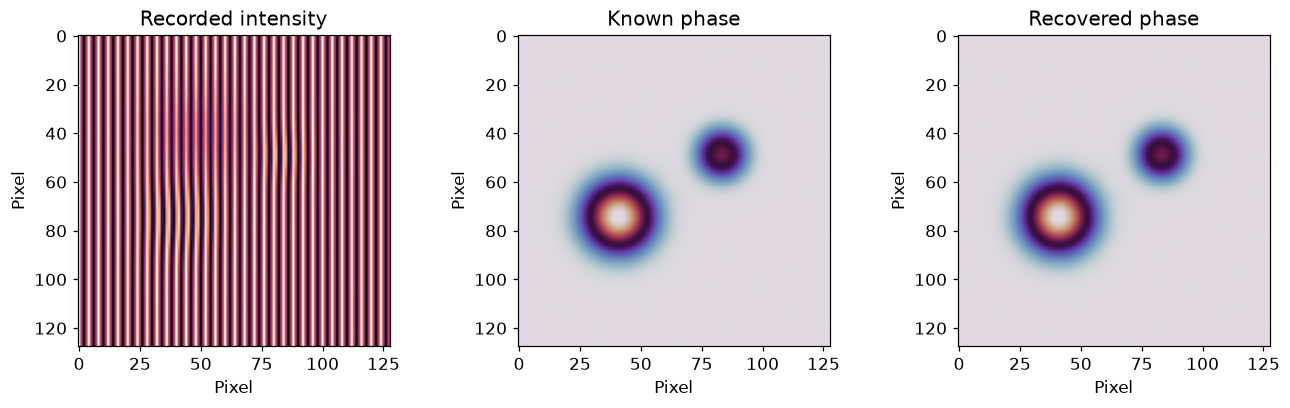

Relative complex-field error with isolated sideband: 4.826320838642857e-15
Carrier 12, crop 8: relative field error 0.00133
Carrier 32, crop 3: relative field error 0.0687
Carrier 60, crop 8: relative field error 0.992


In [2]:
N=128;B=8;carrier=32;A=2.
x=(np.arange(N)-N//2)/N;X,Y=np.meshgrid(x,x)
phase_object=1.1*np.exp(-((X+.18)**2+(Y-.08)**2)/.012)+.7*np.exp(-((X-.15)**2+(Y+.12)**2)/.006)
amplitude=1-.3*np.exp(-((X+.12)**2+(Y+.19)**2)/.02)
bins=np.fft.fftfreq(N)*N;FX,FY=np.meshgrid(bins,bins)
band=np.hypot(FX,FY)<=B
U=np.fft.ifft2(np.fft.fft2(amplitude*np.exp(1j*phase_object))*band)
def hologram_recover(U,carrier=32,radius=8):
    reference=A*np.exp(2j*np.pi*carrier*np.arange(N)/N)[None,:]
    camera=abs(U+reference)**2
    # UR* lies at -carrier. Move it back to zero, then keep its bandwidth.
    sideband=np.roll(np.fft.fft2(camera),carrier,axis=1)*(np.hypot(FX,FY)<=radius)/A
    return camera,np.fft.ifft2(sideband)
camera,recovered=hologram_recover(U)
error=np.linalg.norm(recovered-U)/np.linalg.norm(U)
assert error<1e-12
fig,ax=plt.subplots(1,3,figsize=(12,3.6))
for a,img,title in zip(ax,[camera,np.angle(U),np.angle(recovered)],["Recorded intensity","Known phase","Recovered phase"]):
    a.imshow(img,cmap="twilight" if "phase" in title else "magma");a.set(title=title,xlabel="Pixel",ylabel="Pixel")
show(fig,"01-holographic-recovery")
print("Relative complex-field error with isolated sideband:",error)
for c,r in [(12,8),(32,3),(60,8)]:
    _,bad=hologram_recover(U,c,r)
    print(f"Carrier {c}, crop {r}: relative field error {np.linalg.norm(bad-U)/np.linalg.norm(U):.3g}")

## 2 · A recovered complex field can be refocused

Propagate U with a scalar angular-spectrum transfer function. Here pixels are 1 μm,
wavelength is 0.55 μm, and the object is band-limited to propagating frequencies.
Backward propagation is safe for this noiseless propagating example; amplifying
evanescent components or missing/noisy sidebands is a different inverse problem.

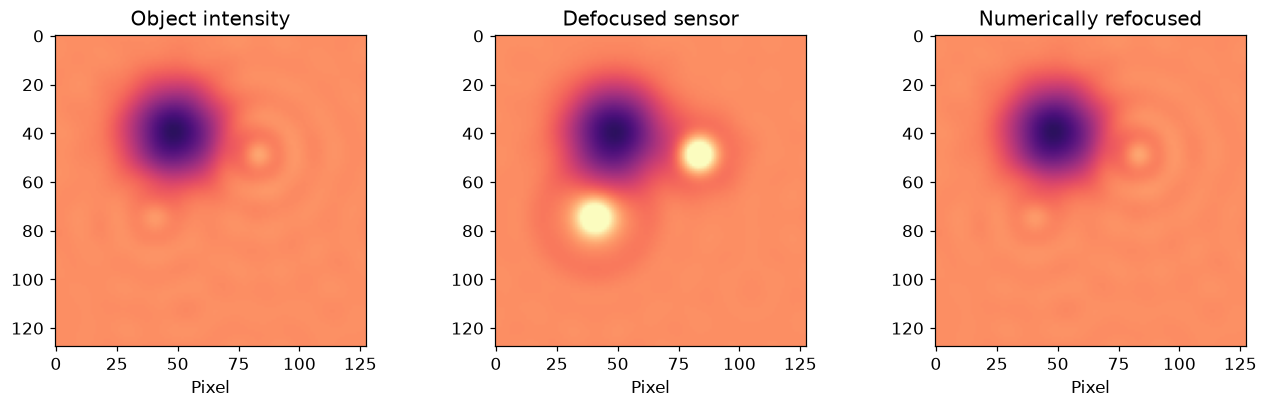

In [3]:
dx=1.;wavelength=.55
def propagate(field,z):
    f=np.fft.fftfreq(N,dx);fx,fy=np.meshgrid(f,f)
    kz=2*np.pi*np.sqrt((1/wavelength**2-fx*fx-fy*fy).astype(complex))
    return np.fft.ifft2(np.fft.fft2(field)*np.exp(1j*kz*z))
z=150.
sensor=propagate(U,z)
_,sensor_recovered=hologram_recover(sensor)
focused=propagate(sensor_recovered,-z)
# Compare up to a global phase, as an unknown reference phase would require.
alignment=np.vdot(U,focused);focused*=np.exp(-1j*np.angle(alignment))
assert np.linalg.norm(focused-U)/np.linalg.norm(U)<1e-12
fig,ax=plt.subplots(1,3,figsize=(12,3.6))
for a,img,title in zip(ax,[abs(U)**2,abs(sensor)**2,abs(focused)**2],["Object intensity","Defocused sensor","Numerically refocused"]):
    a.imshow(img,cmap="magma",vmin=.35,vmax=1.2);a.set(title=title,xlabel="Pixel")
show(fig,"02-refocusing")

## 3 · Recover phase from two magnitude constraints

Without a reference, one intensity plane is insufficient. Gerchberg–Saxton alternates
between planes: keep the current phase but replace the amplitude with a measured or
desired amplitude. This enforces one constraint at a time, not both simultaneously.
A global phase remains undetermined. A low error is evidence of consistency, not uniqueness.

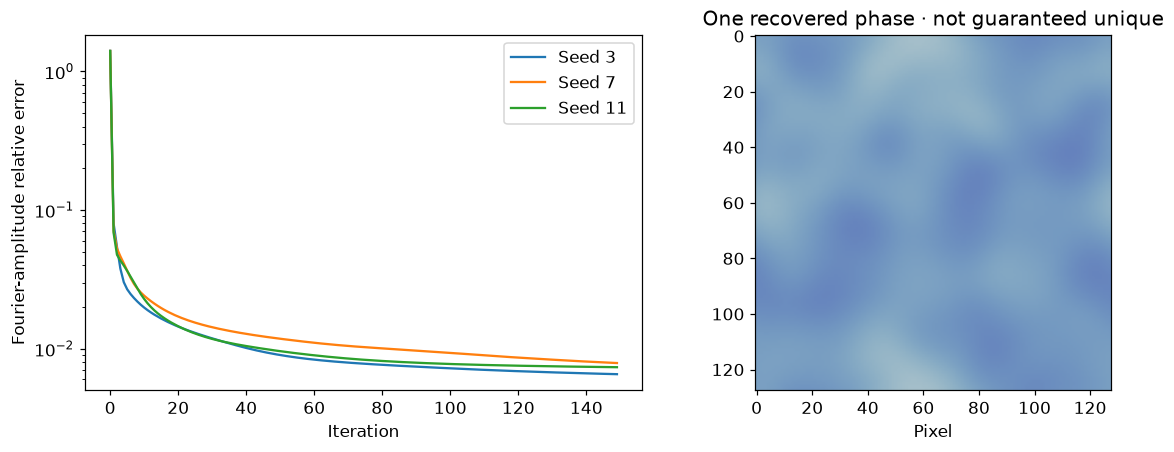

Final magnitude errors: [0.006545125134857436, 0.007876352946562372, 0.007349024349969488]


In [4]:
F=lambda u:np.fft.fft2(u,norm="ortho")
FH=lambda v:np.fft.ifft2(v,norm="ortho")
known_amplitude=abs(U);measured_amplitude=abs(F(U))
def gs(seed,iterations=150):
    random=np.random.default_rng(seed)
    u=known_amplitude*np.exp(1j*random.uniform(-np.pi,np.pi,(N,N)))
    losses=[]
    for _ in range(iterations):
        v=F(u)
        losses.append(np.linalg.norm(abs(v)-measured_amplitude)/np.linalg.norm(measured_amplitude))
        u=known_amplitude*np.exp(1j*np.angle(FH(measured_amplitude*np.exp(1j*np.angle(v)))))
    return u,np.asarray(losses)
results=[gs(seed) for seed in [3,7,11]]
fig,ax=plt.subplots(1,2,figsize=(11,4))
for seed,(u,history) in zip([3,7,11],results):
    ax[0].semilogy(history,label=f"Seed {seed}")
    assert history[-1]<history[0]
    assert np.max(abs(abs(u)-known_amplitude))<1e-12
ax[0].set(xlabel="Iteration",ylabel="Fourier-amplitude relative error");ax[0].legend()
ax[1].imshow(np.angle(results[0][0]),cmap="twilight",vmin=-np.pi,vmax=np.pi)
ax[1].set(title="One recovered phase · not guaranteed unique",xlabel="Pixel")
show(fig,"03-phase-retrieval")
print("Final magnitude errors:",[float(h[-1]) for u,h in results])

## Optional extension · Design, then quantize, a phase-only mask

Replace the measured Fourier amplitude with a target. The pupil has fixed amplitude,
so the requested target may not be exactly feasible. After optimization, quantizing
phase generally worsens the objective: that fabrication constraint was absent from the iterations.

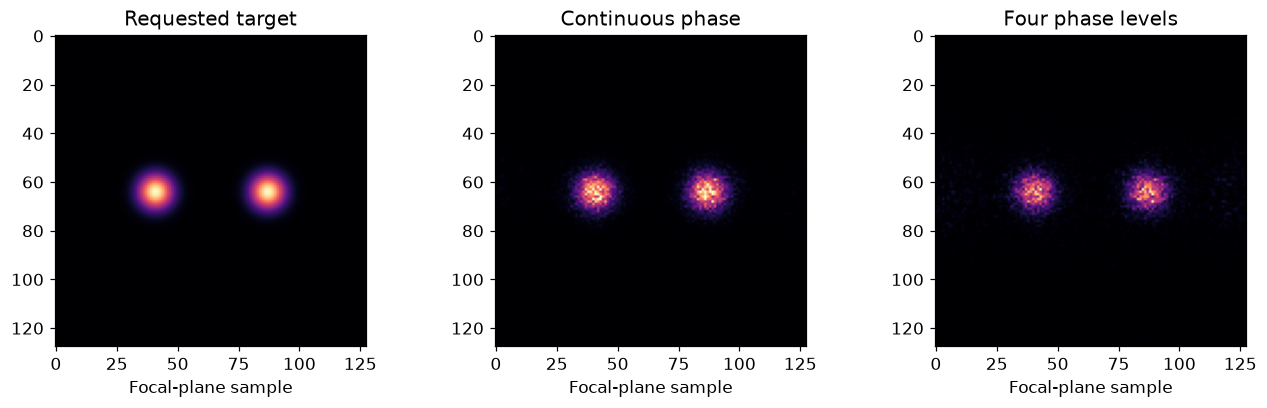

In [5]:
pupil=(X*X+Y*Y<.4**2).astype(float)
target=np.exp(-((X-.18)**2+Y*Y)/.003)+np.exp(-((X+.18)**2+Y*Y)/.003)
target*=np.sum(pupil**2)/target.sum()
u=pupil*np.exp(1j*np.random.default_rng(23).uniform(-np.pi,np.pi,(N,N)))
for _ in range(100):
    v=np.fft.fftshift(F(u))
    u=pupil*np.exp(1j*np.angle(FH(np.fft.ifftshift(np.sqrt(target)*np.exp(1j*np.angle(v))))))
phi=np.angle(u);quantized=np.round(phi/(2*np.pi/4))*(2*np.pi/4)
outputs=[target,abs(np.fft.fftshift(F(u)))**2,abs(np.fft.fftshift(F(pupil*np.exp(1j*quantized))))**2]
fig,ax=plt.subplots(1,3,figsize=(12,3.6))
for a,img,title in zip(ax,outputs,["Requested target","Continuous phase","Four phase levels"]):
    a.imshow(img,cmap="magma",vmin=0,vmax=target.max());a.set(title=title,xlabel="Focal-plane sample")
show(fig,"04-phase-only-design")
assert abs(outputs[1].sum()-pupil.sum())<1e-9

## A short lab report

**1. Budget the spectrum.** For B = 8 and Nyquist = 64 bins, identify a safe carrier interval and explain both bounds.

**2. Compare crops.** Reconstruct with a crop smaller than, equal to, and larger than the object bandwidth.

**3. Test an ambiguity.** Rotate a candidate field by a constant phase and compare its Fourier magnitude.

### Worked reasoning

**Budget the spectrum.** Use 24 < f_c < 56 bins before adding practical margins. The crop must contain B without admitting central or conjugate terms.

**Compare crops.** A small crop smooths the field. An unnecessarily large crop can collect unwanted terms; colour similarity is not a quantitative error test.

**Test an ambiguity.** The magnitude is unchanged. Phase-sensitive comparisons should align global phase when no known reference fixes it.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [Latychevskaia · Iterative phase retrieval for digital holography](https://arxiv.org/abs/1911.07214)
- [TU Delft · Wavefield propagation](https://qiweb.tudelft.nl/aoi/wavefieldpropagation/wavefieldpropagation/)
- [NumPy · Fourier transforms and normalization](https://numpy.org/doc/stable/reference/routines.fft.html)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e05_figures.zip


/tmp/optics-notebooks-xppq4daw/E05/e05_figures.zip